In [2]:
# Cargo los 7 archivos del dataset como tablas de DuckDB para poder usar SQL
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

ruta = '/kaggle/input/datasets/mustafakeser4/looker-ecommerce-bigquery-dataset/'
tablas = ['distribution_centers', 'products', 'users', 'inventory_items', 'order_items', 'orders', 'events']

con = duckdb.connect('/kaggle/working/thelook.duckdb')
for t in tablas:
    con.sql(f"CREATE OR REPLACE VIEW {t} AS SELECT * FROM read_csv_auto('{ruta}{t}.csv')")
    print(t, con.sql(f'SELECT COUNT(*) FROM {t}').fetchone()[0])

distribution_centers 10
products 29120
users 100000
inventory_items 490705
order_items 181759
orders 125226
events 2431963


In [3]:
# Miro desde y hasta cuándo hay pedidos y movimientos de stock
con.sql('''
SELECT MIN(created_at) AS primer_pedido,
       MAX(created_at) AS ultimo_pedido
FROM orders
''').show()

con.sql('''
SELECT MIN(created_at) AS primer_ingreso_stock,
       MAX(sold_at)    AS ultima_venta_stock
FROM inventory_items
''').show()

┌──────────────────────────┬───────────────────────────────┐
│      primer_pedido       │         ultimo_pedido         │
│ timestamp with time zone │   timestamp with time zone    │
├──────────────────────────┼───────────────────────────────┤
│ 2019-01-06 05:30:00+00   │ 2024-01-17 19:46:14.316147+00 │
└──────────────────────────┴───────────────────────────────┘

┌──────────────────────────┬───────────────────────────────┐
│   primer_ingreso_stock   │      ultima_venta_stock       │
│ timestamp with time zone │   timestamp with time zone    │
├──────────────────────────┼───────────────────────────────┤
│ 2018-11-08 04:14:18+00   │ 2024-01-21 18:02:23.533893+00 │
└──────────────────────────┴───────────────────────────────┘



In [4]:
# Pedidos por mes, para ver desde cuándo hay volumen suficiente
mensual = con.sql('''
SELECT date_trunc('month', created_at) AS mes, COUNT(*) AS pedidos
FROM orders
GROUP BY 1
ORDER BY 1
''').df()

print(mensual.head(12).to_string())
print(mensual.tail(3).to_string())   # enero 2024 está incompleto, lo dejo afuera

# Primer mes con al menos 1000 pedidos (es un criterio mío): diciembre 2020
print(mensual[mensual['pedidos'] >= 1000].head(1).to_string())

                         mes  pedidos
0  2019-01-01 00:00:00+00:00       22
1  2019-02-01 00:00:00+00:00       38
2  2019-03-01 00:00:00+00:00       84
3  2019-04-01 00:00:00+00:00      104
4  2019-05-01 00:00:00+00:00      167
5  2019-06-01 00:00:00+00:00      194
6  2019-07-01 00:00:00+00:00      222
7  2019-08-01 00:00:00+00:00      238
8  2019-09-01 00:00:00+00:00      321
9  2019-10-01 00:00:00+00:00      337
10 2019-11-01 00:00:00+00:00      347
11 2019-12-01 00:00:00+00:00      464
                         mes  pedidos
58 2023-11-01 00:00:00+00:00     6915
59 2023-12-01 00:00:00+00:00     8347
60 2024-01-01 00:00:00+00:00     9130
                         mes  pedidos
23 2020-12-01 00:00:00+00:00     1043


In [5]:
# Estados de cada unidad vendida. Voy a sacar Cancelled y Returned de la demanda
con.sql('''
SELECT status, COUNT(*) AS items
FROM order_items
GROUP BY 1
ORDER BY 2 DESC
''').show()

┌────────────┬───────┐
│   status   │ items │
│  varchar   │ int64 │
├────────────┼───────┤
│ Shipped    │ 54440 │
│ Complete   │ 45609 │
│ Processing │ 36388 │
│ Cancelled  │ 27090 │
│ Returned   │ 18232 │
└────────────┴───────┘



In [6]:
# Unidades vendidas por semana y categoría, del 07/12/2020 al 31/12/2023
con.sql('''
CREATE OR REPLACE TABLE demanda_semanal AS
SELECT CAST(date_trunc('week', oi.created_at) AS DATE) AS semana,
       ii.product_category AS categoria,
       COUNT(*) AS unidades,
       SUM(oi.sale_price) AS ingresos,
       SUM(oi.sale_price - ii.cost) AS margen
FROM order_items oi
JOIN inventory_items ii ON ii.id = oi.inventory_item_id
WHERE oi.status NOT IN ('Cancelled', 'Returned')
  AND oi.created_at >= TIMESTAMP '2020-12-07'
  AND oi.created_at <  TIMESTAMP '2024-01-01'
GROUP BY semana, categoria
''')

# Control: debería dar 4061 filas y 26 categorías
con.sql('''
SELECT COUNT(*) AS filas, COUNT(DISTINCT categoria) AS categorias,
       MIN(semana) AS desde, MAX(semana) AS hasta
FROM demanda_semanal
''').show()

┌───────┬────────────┬────────────┬────────────┐
│ filas │ categorias │   desde    │   hasta    │
│ int64 │   int64    │    date    │    date    │
├───────┼────────────┼────────────┼────────────┤
│  4061 │         26 │ 2020-12-07 │ 2023-12-25 │
└───────┴────────────┴────────────┴────────────┘



In [7]:
# Si una categoría no vendió nada una semana, esa fila no existe.
# Armo todas las combinaciones semana x categoría y veo cuáles faltan.
con.sql('''
WITH semanas AS (
    SELECT CAST(s AS DATE) AS semana
    FROM generate_series(TIMESTAMP '2020-12-07', TIMESTAMP '2023-12-25', INTERVAL 7 DAY) AS g(s)
),
categorias AS (
    SELECT DISTINCT categoria FROM demanda_semanal
),
completo AS (
    SELECT s.semana, c.categoria
    FROM semanas s CROSS JOIN categorias c
)
SELECT c.categoria, COUNT(*) AS semanas_sin_ventas
FROM completo c
LEFT JOIN demanda_semanal d
       ON d.semana = c.semana AND d.categoria = c.categoria
WHERE d.semana IS NULL
GROUP BY 1
ORDER BY 2 DESC
''').show()

┌─────────────────────┬────────────────────┐
│      categoria      │ semanas_sin_ventas │
│       varchar       │       int64        │
├─────────────────────┼────────────────────┤
│ Clothing Sets       │                 75 │
│ Jumpsuits & Rompers │                 14 │
│ Suits               │                 10 │
└─────────────────────┴────────────────────┘



In [8]:
# Miro cuándo vendió por primera vez cada una de las 3 categorías con huecos
con.sql('''
SELECT categoria,
       MIN(semana) AS primera_venta,
       MAX(semana) AS ultima_venta,
       COUNT(*) AS semanas_con_ventas,
       ROUND(AVG(unidades), 1) AS unidades_promedio
FROM demanda_semanal
WHERE categoria IN ('Clothing Sets', 'Jumpsuits & Rompers', 'Suits')
GROUP BY 1
''').show()
# Conclusión: arrancaron al principio, así que las semanas sin ventas son demanda cero

┌─────────────────────┬───────────────┬──────────────┬────────────────────┬───────────────────┐
│      categoria      │ primera_venta │ ultima_venta │ semanas_con_ventas │ unidades_promedio │
│       varchar       │     date      │     date     │       int64        │      double       │
├─────────────────────┼───────────────┼──────────────┼────────────────────┼───────────────────┤
│ Jumpsuits & Rompers │ 2020-12-07    │ 2023-12-25   │                146 │               4.0 │
│ Suits               │ 2020-12-14    │ 2023-12-25   │                150 │               4.3 │
│ Clothing Sets       │ 2020-12-21    │ 2023-12-25   │                 85 │               1.6 │
└─────────────────────┴───────────────┴──────────────┴────────────────────┴───────────────────┘



In [9]:
# Armo la tabla final de demanda, con 0 en las semanas sin ventas (COALESCE)
con.sql('''
CREATE OR REPLACE TABLE demanda_completa AS
WITH semanas AS (
    SELECT CAST(s AS DATE) AS semana
    FROM generate_series(TIMESTAMP '2020-12-07', TIMESTAMP '2023-12-25', INTERVAL 7 DAY) AS g(s)
),
categorias AS (
    SELECT DISTINCT categoria FROM demanda_semanal
)
SELECT s.semana, c.categoria,
       COALESCE(d.unidades, 0) AS unidades,
       COALESCE(d.ingresos, 0) AS ingresos,
       COALESCE(d.margen, 0) AS margen
FROM semanas s
CROSS JOIN categorias c
LEFT JOIN demanda_semanal d ON d.semana = s.semana AND d.categoria = c.categoria
''')

# Control: 4160 filas, 99 semanas en cero, 26 categorías
con.sql('''
SELECT COUNT(*) AS filas,
       COUNT(*) FILTER (WHERE unidades = 0) AS semanas_en_cero,
       COUNT(DISTINCT categoria) AS categorias
FROM demanda_completa
''').show()

┌───────┬─────────────────┬────────────┐
│ filas │ semanas_en_cero │ categorias │
│ int64 │      int64      │   int64    │
├───────┼─────────────────┼────────────┤
│  4160 │              99 │         26 │
└───────┴─────────────────┴────────────┘



In [10]:
# Unidades por semana en promedio, por año (2020 tiene solo 4 semanas)
con.sql('''
SELECT EXTRACT(year FROM semana) AS anio,
       COUNT(DISTINCT semana) AS semanas,
       ROUND(SUM(unidades) / COUNT(DISTINCT semana), 0) AS unidades_por_semana
FROM demanda_completa
GROUP BY 1
ORDER BY 1
''').show()

# Variabilidad de cada categoría solo en 2023 (CV = desvío / media)
con.sql('''
SELECT categoria,
       ROUND(AVG(unidades), 1) AS media_52,
       ROUND(STDDEV_SAMP(unidades) / AVG(unidades), 2) AS cv_52
FROM demanda_completa
WHERE semana >= DATE '2023-01-02'
GROUP BY 1
ORDER BY cv_52
''').show()
# Con todo el período el CV da mucho más alto porque la demanda crece:
# por eso uso las últimas 52 semanas

┌───────┬─────────┬─────────────────────┐
│ anio  │ semanas │ unidades_por_semana │
│ int64 │  int64  │       double        │
├───────┼─────────┼─────────────────────┤
│  2020 │       4 │               262.0 │
│  2021 │      52 │               351.0 │
│  2022 │      52 │               610.0 │
│  2023 │      52 │              1226.0 │
└───────┴─────────┴─────────────────────┘

┌───────────────────────────────┬──────────┬────────┐
│           categoria           │ media_52 │ cv_52  │
│            varchar            │  double  │ double │
├───────────────────────────────┼──────────┼────────┤
│ Shorts                        │     74.0 │    0.3 │
│ Plus                          │     29.6 │    0.3 │
│ Swim                          │     77.1 │    0.3 │
│ Sleep & Lounge                │     74.2 │   0.31 │
│ Fashion Hoodies & Sweatshirts │     79.3 │   0.32 │
│ Tops & Tees                   │     78.8 │   0.32 │
│ Jeans                         │     86.0 │   0.32 │
│ Socks                    

In [11]:
# ABC por ingresos acumulados (A hasta 80%, B hasta 95%, C el resto)
# XYZ por variabilidad (X hasta 0.5, Y hasta 1.0, Z el resto). Los cortes son convención.
con.sql('''
CREATE OR REPLACE TABLE segmentos AS
WITH base AS (
    SELECT categoria,
           SUM(ingresos) AS ingresos,
           AVG(unidades) AS media,
           STDDEV_SAMP(unidades) AS desvio
    FROM demanda_completa
    WHERE semana >= DATE '2023-01-02'
    GROUP BY 1
),
acum AS (
    SELECT *,
           SUM(ingresos) OVER (ORDER BY ingresos DESC) / SUM(ingresos) OVER () AS pct_acum
    FROM base
)
SELECT categoria,
       ROUND(ingresos) AS ingresos,
       ROUND(media, 1) AS media_semanal,
       ROUND(desvio / media, 2) AS cv,
       CASE WHEN pct_acum <= 0.80 THEN 'A' WHEN pct_acum <= 0.95 THEN 'B' ELSE 'C' END AS abc,
       CASE WHEN desvio / media <= 0.5 THEN 'X' WHEN desvio / media <= 1.0 THEN 'Y' ELSE 'Z' END AS xyz
FROM acum
''')

print(con.sql('SELECT * FROM segmentos ORDER BY ingresos DESC').df().to_string())

                        categoria  ingresos  media_semanal    cv abc xyz
0               Outerwear & Coats  467006.0           61.4  0.34   A   X
1                           Jeans  441492.0           86.0  0.32   A   X
2                        Sweaters  300254.0           75.5  0.34   A   X
3             Suits & Sport Coats  231624.0           35.1  0.39   A   X
4   Fashion Hoodies & Sweatshirts  228337.0           79.3  0.32   A   X
5                            Swim  223819.0           77.1  0.30   A   X
6                  Sleep & Lounge  188351.0           74.2  0.31   A   X
7                          Shorts  177852.0           74.0  0.30   A   X
8                         Dresses  171452.0           37.8  0.34   A   X
9                     Tops & Tees  168904.0           78.8  0.32   A   X
10                      Intimates  165155.0           91.6  0.33   A   X
11                         Active  164292.0           62.1  0.32   A   X
12                          Pants  152475.0        

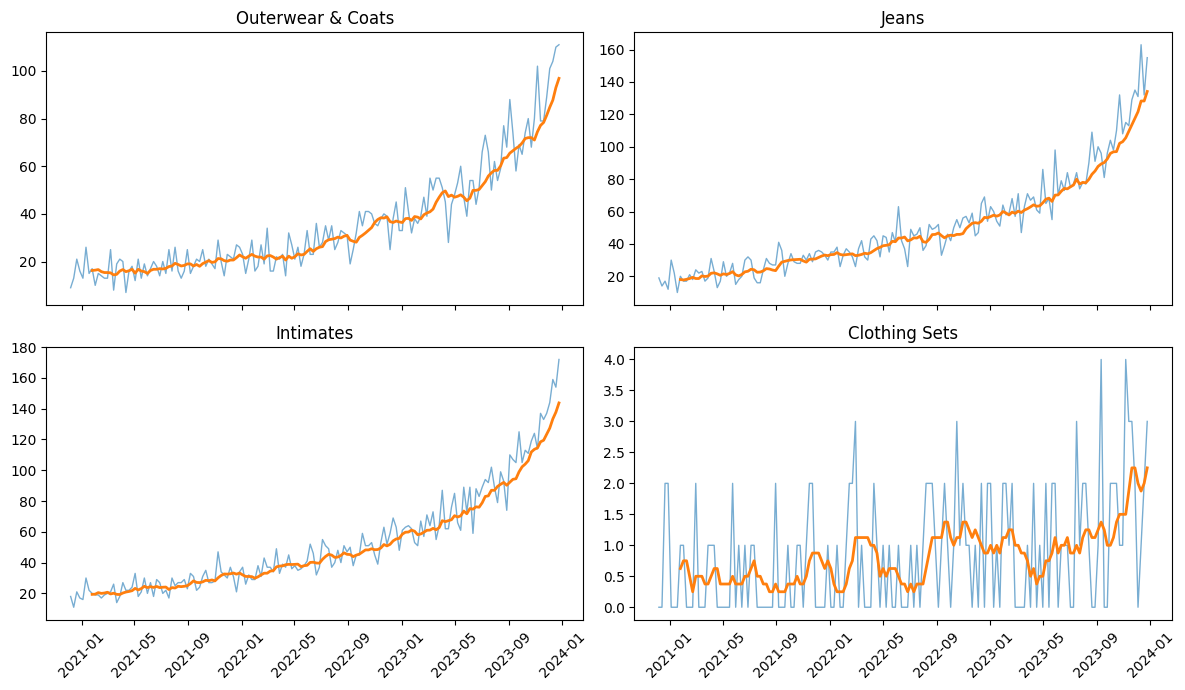

In [12]:
# Demanda semanal de 4 categorías elegidas a propósito:
# - Outerwear & Coats y Jeans: las dos que más facturan en 2023
# - Intimates: la que más unidades vende por semana
# - Clothing Sets: la que casi no vende, para ver cómo es una demanda esporádica
# La línea gruesa es el promedio de las últimas 8 semanas, para ver la tendencia sin el ruido
df = con.sql('SELECT * FROM demanda_completa ORDER BY semana').df()
df['semana'] = pd.to_datetime(df['semana'])
elegidas = ['Outerwear & Coats', 'Jeans', 'Intimates', 'Clothing Sets']

fig, ejes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, cat in zip(ejes.ravel(), elegidas):
    s = df[df['categoria'] == cat].set_index('semana')['unidades'].sort_index()
    ax.plot(s.index, s.values, linewidth=1, alpha=0.6)
    ax.plot(s.index, s.rolling(8).mean(), linewidth=2)
    ax.set_title(cat)
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

In [16]:
# Tabla con una fila por semana y una columna por categoría (la usan las celdas que siguen)
df = con.sql('SELECT * FROM demanda_completa ORDER BY semana').df()
tabla = df.pivot(index='semana', columns='categoria', values='unidades')
print(tabla[['Jeans', 'Intimates', 'Outerwear & Coats']].tail(3))   # tabla: una fila por semana

# Comparo dos formas simples de pronosticar la semana siguiente, en las últimas 12 semanas
real = tabla.tail(12)                                          # lo que realmente se vendió
pron_semana_anterior = tabla.shift(1).tail(12)                 # A: lo vendido la semana anterior
pron_promedio_8 = tabla.rolling(8).mean().shift(1).tail(12)    # B: promedio de las 8 semanas anteriores

# Error de cada método, como % de lo vendido (más bajo = mejor)
error_A = (real - pron_semana_anterior).abs().sum() / real.sum() * 100
error_B = (real - pron_promedio_8).abs().sum() / real.sum() * 100

comparacion = pd.DataFrame({'A_semana_anterior': error_A, 'B_promedio_8': error_B}).round(1)
print(comparacion)
print('Categorías donde gana A:', (error_A < error_B).sum(), 'de', len(comparacion))

categoria   Jeans  Intimates  Outerwear & Coats
semana                                         
2023-12-11    163        159                104
2023-12-18    132        154                110
2023-12-25    155        172                111
                               A_semana_anterior  B_promedio_8
categoria                                                     
Accessories                                 12.3          12.2
Active                                      13.8          12.3
Blazers & Jackets                           25.9          22.6
Clothing Sets                               45.8          52.1
Dresses                                     11.4          13.5
Fashion Hoodies & Sweatshirts               12.0          14.1
Intimates                                    6.7          12.6
Jeans                                       12.2          13.3
Jumpsuits & Rompers                         39.3          34.4
Leggings                                    25.6          17.0
Mate

In [14]:
# Supuestos (no están en los datos, los elijo yo)
plazo = 2        # semanas que tarda en llegar un pedido
revision = 1     # reviso el stock una vez por semana
z = 1.645        # nivel de servicio del 95 %

# Cuánto se equivoca la regla simple, en unidades (últimas 12 semanas)
real = tabla.tail(12)
pron = tabla.shift(1).tail(12)
error_tipico = ((real - pron) ** 2).mean() ** 0.5

demanda_esperada = tabla.iloc[-1]     # lo que se vendió la última semana

stock_seguridad = z * error_tipico * (plazo + revision) ** 0.5
punto_de_pedido = demanda_esperada * plazo + z * error_tipico * plazo ** 0.5
stock_objetivo = demanda_esperada * (plazo + revision) + stock_seguridad

resumen = pd.DataFrame({
    'demanda_esperada': demanda_esperada,
    'error_tipico': error_tipico,
    'stock_seguridad': stock_seguridad,
    'punto_de_pedido': punto_de_pedido,
    'stock_objetivo': stock_objetivo,
})

# Le pego las clases ABC/XYZ y ordeno
seg = con.sql('SELECT categoria, abc, xyz FROM segmentos').df().set_index('categoria')
resumen = seg.join(resumen).sort_values(['abc', 'demanda_esperada'], ascending=[True, False]).round(0)

print(resumen.to_string())
resumen.to_csv('/kaggle/working/stock_objetivo.csv')
# Ojo: Clothing Sets casi no vende (1 unidad por semana) y esta fórmula no le sirve

                              abc xyz  demanda_esperada  error_tipico  stock_seguridad  punto_de_pedido  stock_objetivo
categoria                                                                                                              
Intimates                       A   X               172          11.0             31.0            369.0           547.0
Jeans                           A   X               155          19.0             53.0            353.0           518.0
Tops & Tees                     A   X               151          17.0             49.0            342.0           502.0
Fashion Hoodies & Sweatshirts   A   X               143          17.0             50.0            327.0           479.0
Sweaters                        A   X               138          16.0             47.0            314.0           461.0
Shorts                          A   X               131          17.0             49.0            302.0           442.0
Sleep & Lounge                  A   X   

In [17]:
print(pd.read_csv('/kaggle/working/stock_objetivo.csv').shape)

(26, 8)
